In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, LSTM, Bidirectional, Dropout, Dense
from tensorflow.keras.layers import MultiHeadAttention, Add, LayerNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.layers import *
from xml.parsers.expat import model
from tensorflow.keras.models import load_model
import tensorflow as tf
import os

X_train = np.load("x_train_aug.npy")
Y_train = np.load("y_train_aug.npy")
X_val = np.load("X_val.npy")
Y_val = np.load("y_val.npy")
X_test = np.load("X_test.npy")
Y_test = np.load("y_test.npy")

In [2]:
from tensorflow.keras.utils import to_categorical

actions = list(np.unique(Y_train))
num_class = len(np.unique(Y_train))

y_train = to_categorical(Y_train).astype(int)
y_test = to_categorical(Y_test).astype(int)
y_val = to_categorical(Y_val).astype(int)


In [3]:
inputs = Input(shape=(X_train.shape[1], X_train.shape[2]))
x = Conv1D(128, 3, padding="same", activation="swish")(inputs)
x = Dropout(0.1)(x)

x = Conv1D(128, 5, padding="same", activation="swish")(x)

x = Bidirectional(LSTM(64, return_sequences=True))(x)

attn1 = MultiHeadAttention(num_heads=4, key_dim=64)(x, x)
x = Add()([x, attn1])
x = LayerNormalization(epsilon=1e-6)(x)
ff = Dense(128, activation='swish')(x)
ff = Dense(x.shape[-1])(ff)

attn2 = MultiHeadAttention(num_heads=8, key_dim=32)(x, x)
x = Add()([x, attn2])
x = LayerNormalization(epsilon=1e-6)(x)
ff = Dense(128, activation='swish')(x)
ff = Dense(x.shape[-1])(ff)

x = LSTM(128, return_sequences=False)(x)

x = Dense(64, activation='relu')(x)
x = Dense(32, activation='relu')(x)
outputs = Dense(num_class, activation='softmax')(x)
model = Model(inputs, outputs)

In [4]:
from tensorflow.keras.optimizers import Adam
optimizer = Adam(learning_rate= 1e-4)
model.compile(optimizer=optimizer,
              loss= 'categorical_crossentropy',
              metrics=['categorical_accuracy'])

In [5]:
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint
from tensorflow.keras.callbacks import ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'model.h5',
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose = 1
)
reducer_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)

In [6]:
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, checkpoint, reducer_lr]
)

Epoch 1/50


87/87 [==============================] - ETA: 0s - loss: 1.4581 - categorical_accuracy: 0.6898
Epoch 1: val_loss improved from inf to 0.75093, saving model to model.h5


c:\Users\DELL\Desktop\training\venv\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


87/87 [==============================] - 24s 129ms/step - loss: 1.4581 - categorical_accuracy: 0.6898 - val_loss: 0.7509 - val_categorical_accuracy: 0.9013 - lr: 1.0000e-04
Epoch 2/50
87/87 [==============================] - ETA: 0s - loss: 0.3369 - categorical_accuracy: 0.9784
Epoch 2: val_loss improved from 0.75093 to 0.12189, saving model to model.h5
87/87 [==============================] - 9s 97ms/step - loss: 0.3369 - categorical_accuracy: 0.9784 - val_loss: 0.1219 - val_categorical_accuracy: 1.0000 - lr: 1.0000e-04
Epoch 3/50
87/87 [==============================] - ETA: 0s - loss: 0.0698 - categorical_accuracy: 1.0000
Epoch 3: val_loss improved from 0.12189 to 0.04476, saving model to model.h5
87/87 [==============================] - 8s 97ms/step - loss: 0.0698 - categorical_accuracy: 1.0000 - val_loss: 0.0448 - val_categorical_accuracy: 1.0000 - lr: 1.0000e-04
Epoch 4/50
87/87 [==============================] - ETA: 0s - loss: 0.0314 - categorical_accuracy: 1.0000
Epoch 4: val_

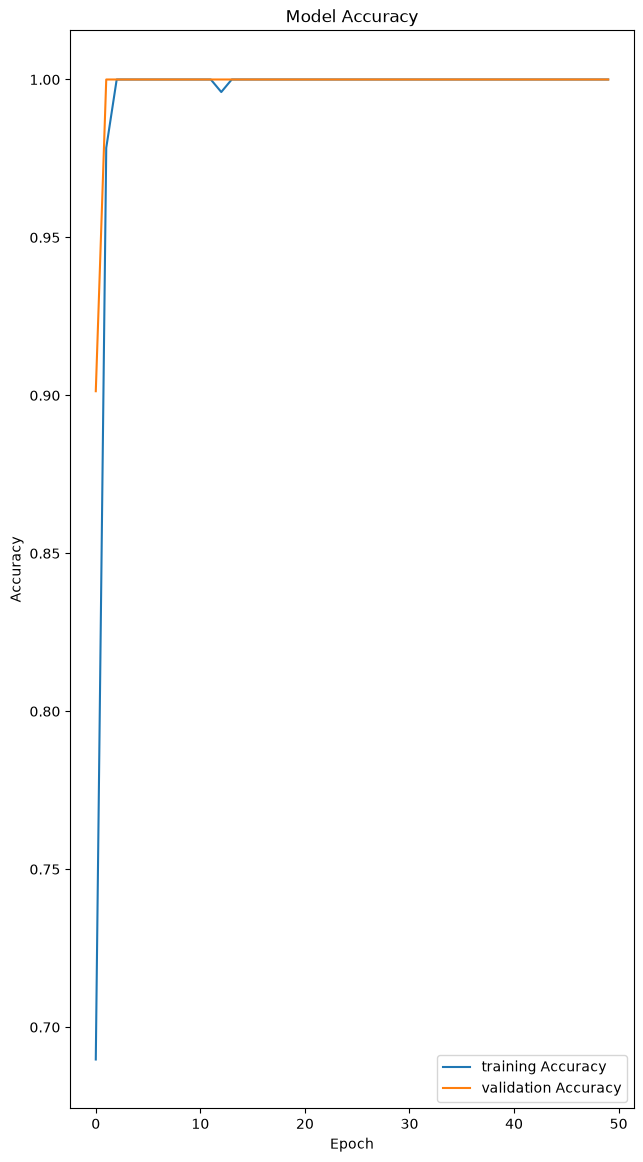

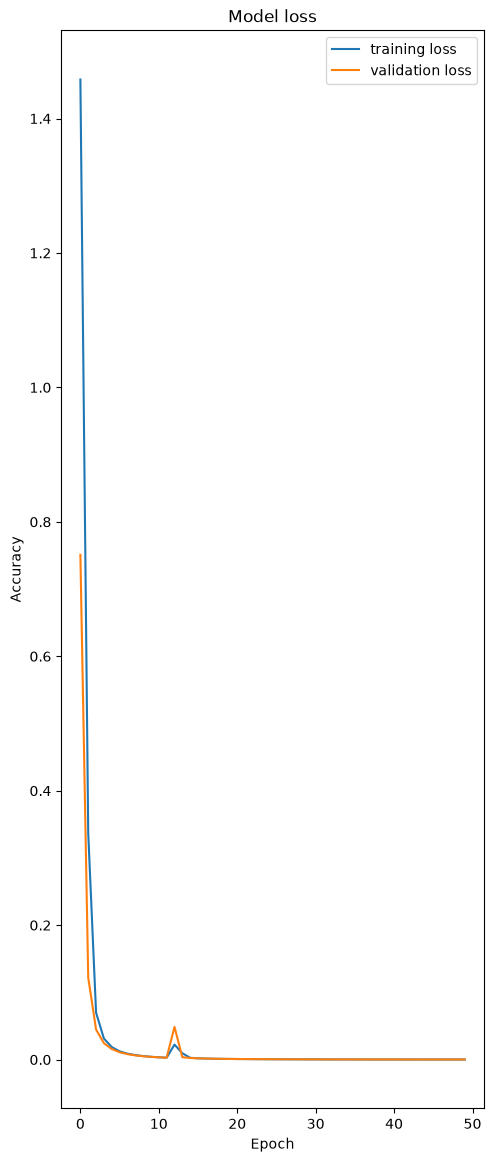

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize = (16,14))
plt.subplot(1,2,1)
plt.plot(history.history['categorical_accuracy'],label='training Accuracy')
plt.plot(history.history['val_categorical_accuracy'],label='validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.figure(figsize = (12,14))
plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

16/16 [==============================] - 1s 32ms/step - loss: 0.1189 - categorical_accuracy: 0.9423
Test Accuracy: 0.942345917224884
16/16 [==============================] - 2s 34ms/step


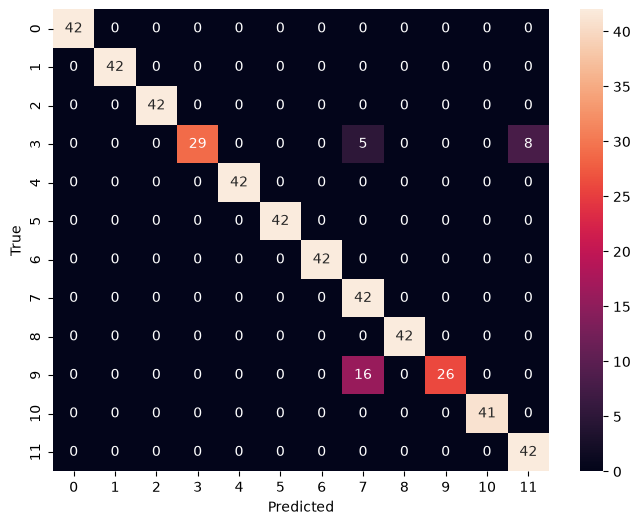

In [11]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns


loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)
y_pred = model.predict(X_test)


y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)



cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [16]:
from google.colab import drive
drive.mount('/content/drive')

model.save('/content/drive/MyDrive/my_model.h5')

from google.colab import files

files.download("my_model.h5")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>